## **Summary**

### 1. Data selection and preprocessing

### 2. Selected clusterings run

### 3. Visualization of features and trajectories

### 4. Conclusions

In [1]:
import import_first

from common import (deploy_utils, feature_utils, plot_utils, cluster_utils)

from pathlib import PurePath

import time
import numpy as np
import matplotlib.pyplot as plt

import pickle

## **1. Get data**

In [2]:
trace = deploy_utils.Trace.read_trace(
    file_path=PurePath("..") / ".." / "data" / "6_to_8am.csv")
print("trace summary:\n" + deploy_utils.Trace.summarize_trace(trace=trace))

trace summary:
[+] number of vehicles: 75516
[+] number of lines: 2182717
[+] x interval: [0, 99]
[+] y interval: [0, 99]


In [3]:
cell_df = feature_utils.Features.create_basic_cell_df(trace=trace)

In [4]:
cell_df.head()

,start_c,end_c,avg_dwell_time,pop
x:y,,,,
0:43,0,0,26.666667,3
10:28,0,0,10.000000,6
10:29,0,0,10.000000,17
10:32,0,0,12.500000,8
10:33,0,0,43.333333,12


In [5]:
v_df = feature_utils.Features.create_basic_vehicle_df(trace=trace)

In [6]:
v_df.head()

,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
vehicle_id,,,,,
0,280,16,0.057143,3.166598,3.896292
1,660,35,0.053030,9.093438,4.847520
2,400,27,0.067500,6.107182,4.534184
3,230,14,0.060870,2.945942,3.675311
4,740,41,0.055405,9.749632,5.136696


### 1.1 Preprocessing

In [7]:
cell_df, _ = cluster_utils.Preprocessing.do_standard_scale(df=cell_df, features=cell_df.columns.tolist())

In [8]:
cell_df.head()

,start_c,end_c,avg_dwell_time,pop
x:y,,,,
0:43,-0.733131,-0.449962,0.586733,-0.612063
10:28,-0.733131,-0.449962,-0.846835,-0.608488
10:29,-0.733131,-0.449962,-0.846835,-0.595379
10:32,-0.733131,-0.449962,-0.631800,-0.606104
10:33,-0.733131,-0.449962,2.020302,-0.601338


In [9]:
v_df, _ = cluster_utils.Preprocessing.do_standard_scale(df=v_df, features=v_df.columns.tolist())

In [10]:
v_df.head()

,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
vehicle_id,,,,,
0,-0.956085,-0.685207,0.686673,-0.692637,-0.222071
1,0.205044,0.323697,0.378576,0.711783,0.675063
2,-0.589413,-0.101105,1.462592,0.004162,0.379546
3,-1.108865,-0.791407,0.965864,-0.744924,-0.430485
4,0.449492,0.642298,0.556510,0.867275,0.947794


## **2. Clustering**

Sample 20% of vehicles

In [11]:
import random
rng = random.Random(x=123)
v_samples = rng.sample(population=v_df.index.tolist(), k=int(len(v_df) * 0.2))

In [12]:
v_df_reduced = v_df.loc[v_samples]

In [13]:
clust_res, model, score, _ = cluster_utils.Clustering.run_kmeans(
    df=v_df_reduced, features=["entropy", "radius_of_gyration", "trip_duration"],
    k=3, n_runs=100)

In [14]:
clust_res["cluster"].value_counts()

cluster
2    6383
1    5068
0    3652
Name: count, dtype: int64

In [15]:
clust_res["cluster"].value_counts() / len(clust_res)

cluster
2    0.422631
1    0.335562
0    0.241806
Name: count, dtype: float64

In [16]:
print(score)

0.432888181861984


## **3. Features and trajectories visualization**

### 3.1 Vehicles' features visualization (entire dataset)

array([[<Axes: title={'center': 'trip_duration'}>,
        <Axes: title={'center': 'radius_of_gyration'}>],
       [<Axes: title={'center': 'entropy'}>, <Axes: >]], dtype=object)

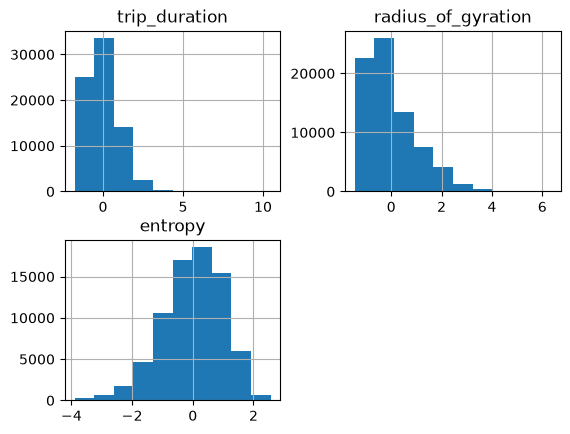

In [17]:
v_df[["trip_duration", "radius_of_gyration", "entropy"]].hist()

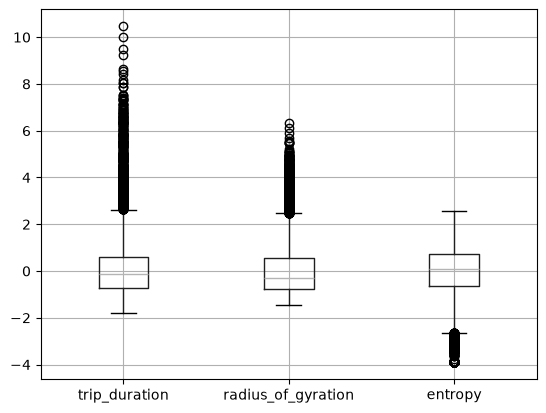

In [18]:
v_df[["trip_duration", "radius_of_gyration", "entropy"]].boxplot()
plt.show()

In [19]:
v_df[["trip_duration", "radius_of_gyration", "entropy"]].describe().loc[["25%", "75%"]]

,trip_duration,radius_of_gyration,entropy
25%,-0.742193,-0.748304,-0.626115
75%,0.602273,0.548252,0.737486


### 3.2 Vehicles' features visualization (clusters)

Cluster 0


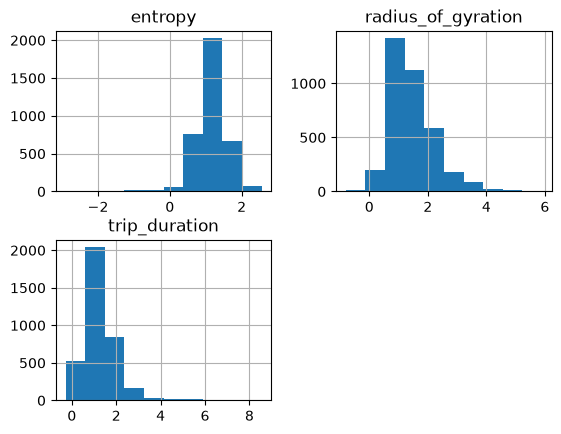

Cluster 1


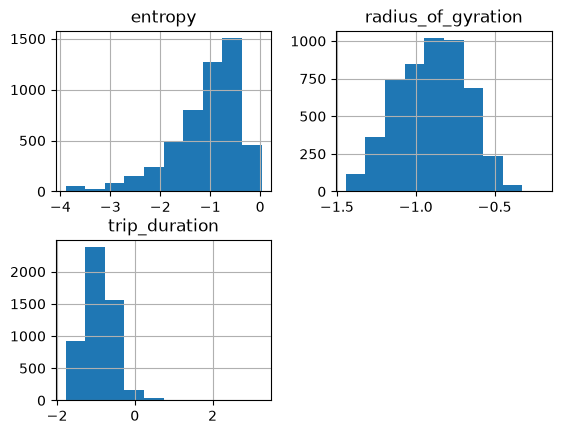

Cluster 2


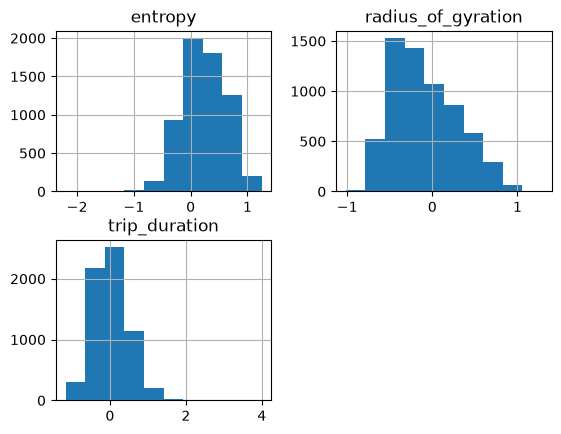

In [20]:
for cluster_id in (0, 1, 2):

    print(f"Cluster {cluster_id}")
    clust_res[clust_res["cluster"] == cluster_id] \
    [["entropy", "radius_of_gyration", "trip_duration"]].hist()
    plt.show()

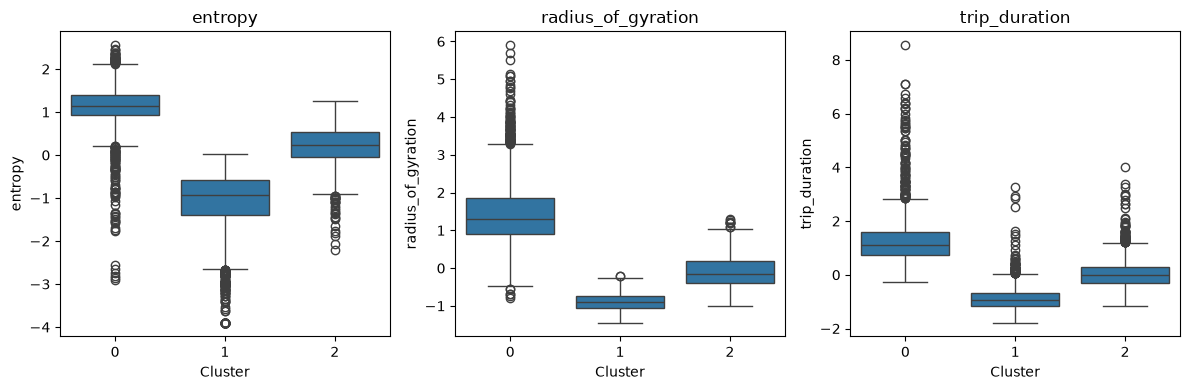

In [21]:
plot_utils.Plot.plot_cluster_feature_boxplots(
    df=clust_res, features=["entropy", "radius_of_gyration", "trip_duration"],
    figsize=(12, 4))
plt.show()

In [22]:
for cluster_id in (0, 1, 2):
    print(f"Cluster {cluster_id}")
    print(clust_res[clust_res["cluster"] == cluster_id][["entropy", "radius_of_gyration", "trip_duration"]]
          .describe().loc[["25%", "75%"]])

Cluster 0
      entropy  radius_of_gyration  trip_duration
25%  0.924423            0.906246       0.755053
75%  1.404987            1.861002       1.587705
Cluster 1
      entropy  radius_of_gyration  trip_duration
25% -1.404190           -1.060218      -1.169977
75% -0.571164           -0.734888      -0.681081
Cluster 2
      entropy  radius_of_gyration  trip_duration
25% -0.049123           -0.389101      -0.314408
75%  0.533669            0.191932       0.296712


### 3.3 Full trajectories and cluster trajectories

In [23]:
trace_reduced = trace[trace["vehicle_id"].isin(v_samples)]
trace_reduced.head()

,vehicle_id,time_instant,x,y,cell_dwell_time
92,4,23770,38,77,20
93,4,23790,37,77,20
94,4,23810,38,77,10
95,4,23820,39,76,20
96,4,23840,40,75,20


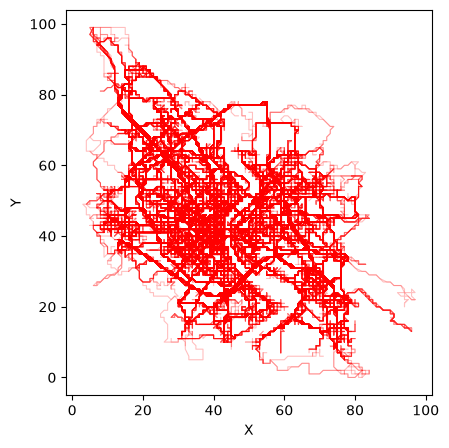

In [24]:
plot_utils.Plot.plot_vehicle_trajectories(
    trace=trace_reduced, figsize=(5, 5))
plt.show()

In [25]:
for c in (0, 1, 2):
    print("CLUSTER", c)
    print(clust_res[clust_res["cluster"] == c].describe().loc[["25%", "50%"]])
    print()

CLUSTER 0
      entropy  radius_of_gyration  trip_duration  cluster
25%  0.924423            0.906246       0.755053      0.0
50%  1.148492            1.304145       1.121725      0.0

CLUSTER 1
      entropy  radius_of_gyration  trip_duration  cluster
25% -1.404190           -1.060218      -1.169977      1.0
50% -0.919068           -0.890718      -0.925529      1.0

CLUSTER 2
      entropy  radius_of_gyration  trip_duration  cluster
25% -0.049123           -0.389101      -0.314408      2.0
50%  0.224386           -0.150881      -0.008848      2.0



In [57]:
import importlib
importlib.reload(plot_utils)

<module 'common.plot_utils' from '/home/bernardo/cluster_serv/common/plot_utils.py'>


Cluster 0
Num Vehicles: 3652 (24.18 %)

Cluster 1
Num Vehicles: 5068 (33.56 %)

Cluster 2
Num Vehicles: 6383 (42.26 %)


/tmp/ipykernel_113854/3576042463.py:28: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


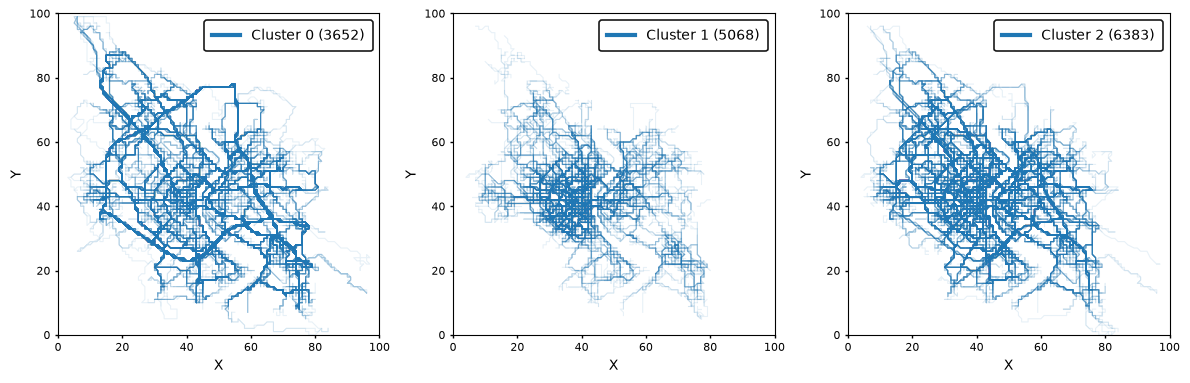

In [58]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(12, 4), constrained_layout=True)
for cluster_id in (0, 1, 2):

    to_plot = clust_res[clust_res["cluster"] == cluster_id]
    print()
    print(f"Cluster {cluster_id}")
    print(f"Num Vehicles: {len(to_plot)} ({100 * len(to_plot)/trace_reduced["vehicle_id"].nunique():.2f} %)")
    plot_utils.Plot.plot_trajectories_by_cluster(
        trace=trace_reduced, clusters=to_plot.reset_index(names="vehicle_id"), ax=ax[cluster_id], alpha=0.1)

    ax[cluster_id].tick_params(
        axis="both",
        which="major",
        labelsize=8,   # tick label size
        length=2,       # tick mark length
        width=1.0       # tick mark thickness
    )

    ax[cluster_id].set_xlim(0, 100)
    ax[cluster_id].set_ylim(0, 100)

    ax[cluster_id].set_xticks([0, 20, 40, 60, 80, 100])
    ax[cluster_id].set_yticks([0, 20, 40, 60, 80, 100])

    ax[cluster_id].set_aspect("equal")
    ax[cluster_id].set_box_aspect(1)

plt.tight_layout()
plt.savefig("veic_clust.png")
plt.show()

In [27]:
trace_reduced["vehicle_id"].nunique()

15103

In [28]:
t = trace_reduced.copy()
t["cell_dwell_time"] //= 10
t.to_csv(path_or_buf="v_trace_reduced.csv", sep=";",
                     index=False, header=False, lineterminator=";\n")

In [29]:
t

,vehicle_id,time_instant,x,y,cell_dwell_time
92,4,23770,38,77,2
93,4,23790,37,77,2
94,4,23810,38,77,1
95,4,23820,39,76,2
96,4,23840,40,75,2
...,...,...,...,...,...
2182480,75509,23450,16,40,4
2182481,75509,23490,17,39,1
2182482,75509,23500,17,38,2
2182483,75509,23520,17,37,2


In [30]:
trace_reduced

,vehicle_id,time_instant,x,y,cell_dwell_time
92,4,23770,38,77,20
93,4,23790,37,77,20
94,4,23810,38,77,10
95,4,23820,39,76,20
96,4,23840,40,75,20
...,...,...,...,...,...
2182480,75509,23450,16,40,40
2182481,75509,23490,17,39,10
2182482,75509,23500,17,38,20
2182483,75509,23520,17,37,20


In [31]:
trace_reduced

,vehicle_id,time_instant,x,y,cell_dwell_time
92,4,23770,38,77,20
93,4,23790,37,77,20
94,4,23810,38,77,10
95,4,23820,39,76,20
96,4,23840,40,75,20
...,...,...,...,...,...
2182480,75509,23450,16,40,40
2182481,75509,23490,17,39,10
2182482,75509,23500,17,38,20
2182483,75509,23520,17,37,20


In [32]:
trace_reduced.reset_index(drop=True)

,vehicle_id,time_instant,x,y,cell_dwell_time
0,4,23770,38,77,20
1,4,23790,37,77,20
2,4,23810,38,77,10
3,4,23820,39,76,20
4,4,23840,40,75,20
...,...,...,...,...,...
440219,75509,23450,16,40,40
440220,75509,23490,17,39,10
440221,75509,23500,17,38,20
440222,75509,23520,17,37,20


In [33]:
deploy_utils.Trace.read_trace(file_path="v_trace_reduced.csv").equals(trace_reduced.reset_index(drop=True))

True

In [34]:
deploy_utils.Trace.read_trace(file_path="v_trace_reduced.csv")["vehicle_id"].nunique()

15103

In [35]:
clust_res.index.__len__()

15103

In [36]:
clust_res.head()

,entropy,radius_of_gyration,trip_duration,cluster
vehicle_id,,,,
6863,-0.411443,-0.558798,-0.864417,1
35084,-0.195774,-0.668550,-0.100516,2
11427,0.757937,0.699495,0.449492,2
53377,-0.281942,-0.711505,-0.650525,1
34937,1.348572,2.128323,0.602273,0


In [37]:
clust_res.reset_index(names="vehicle_id")[["vehicle_id", "cluster"]] \
    .to_csv("vc_from_v.csv", index=False, sep=";", header=False)

## **Conclusions**

- Vehicles' clusters show a behavaior separation that is explainable
- Clusters' different dominant trajectories justify differences in time, entropy and radius of gyration
- Some parallels can be made with cell induced vehicle clusters and vehicle clusters themselves
    - cluster_c[0] vs cluster_v[0]
    - cluster_c[1] vs cluster_v[1]
    - cluster_c[2] vs cluster_v[2]